<a href="https://colab.research.google.com/github/JuanMAleman/Practicas-IA/blob/main/Practica2/notebooks/Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 1. Comprensión del dominio del dataset.

En esta primera parte se hizo un análisis de los datos que aparecen en nuestro dataset, se identificaron tipos de datos, valores y celdas vacías.

In [38]:
import pandas as pd

url="https://raw.githubusercontent.com/FabsRobles/Practica2-IA/refs/heads/main/train.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Teniendo la tabla de valores ahora inspeccionamos los tipos de datos con los que contamos, qué contiene cáda columna y sus valores importantes.

### 1. ¿Cuál es el nombre de las columnas?

In [39]:
df.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked']

### 2. ¿Qué representa cada columna?

In [4]:
datos={
    'Columna': ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
    'Descripción': ['Identificador único del pasajero', 'Indica si el pasajero sobrevivió (1) o no (0)', 'Clase del boleto: Primera, Segunda o Tercera0', 'Nombre del pasajero', 'Sexo(male/female)', 'Edad en años', 'Cuántos hermanos o espos@ iban abordo', 'Cuántos padres o hijos iban abordo', 'Número de boleto', 'Lo que pagó por el boleto', 'Número de camarote', 'Puerto donde abordó: C,Q o S'],
    'Tipo de dato': ['Entero', 'Entero', 'Entero', 'Texto', 'Texto', 'Flotante', 'Entero', 'Entero', 'Texto', 'Flotante', 'Texto', 'Texto']
}

df=pd.DataFrame(datos)

df

,Columna,Descripción,Tipo de dato
0,PassengerId,Identificador único del pasajero,Entero
1,Survived,Indica si el pasajero sobrevivió (1) o no (0),Entero
2,Pclass,"Clase del boleto: Primera, Segunda o Tercera0",Entero
3,Name,Nombre del pasajero,Texto
4,Sex,Sexo(male/female),Texto
5,Age,Edad en años,Flotante
6,SibSp,Cuántos hermanos o espos@ iban abordo,Entero
7,Parch,Cuántos padres o hijos iban abordo,Entero
8,Ticket,Número de boleto,Texto
9,Fare,Lo que pagó por el boleto,Flotante


### 3. ¿Cuántos datos faltantes hay en cada columna?

In [36]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


### 4. ¿Hay filas repetidas?

In [37]:
df.duplicated().sum()

np.int64(0)

Después de inspeccionar en qué condiciones se encuentra nuestro dataset, respondemos a las siguientes preguntas.

*   ¿Qué representa cada fila?
> Cada fila de nuestro dataset representa a un pasajero del Titanic.

*   ¿La variable objetivo estaría disponible en un escenario real?
> No, ya que la unica forma de saber si alguien sobrevivió es después del hundimiento, no antes.


*   ¿Existen identificadores o variables con fuga de información?
> La variable Survived contiene la información que requerimos para el análisis, sin embargo en un caso real, esa variable solo estará llena después del hundimiento del barco.


*   ¿Qué decisiones podrían afectar de forma desigual a distintos grupos?
> Si un modelo usara las variables Sex, Age, Pclass, podría favorecer o perjudicar a mujeres, niños o personas de clase baja.







# Actividad 2. Data Profiling

Antes de comenzar dividimos las columnas en grupos de la siguiente manera.

In [7]:
col_num=["Age", "SibSp", "Parch", "Fare"]
col_cat=["Survived", "Pclass", "Sex", "Embarked", "Cabin"]
col_id= ["PassengerId", "Name", "Ticket"]

Lo dividimos de esta forma ya que a pesar de que las variables como "Survived" y "Pclass" parecen números son categorías, ya que no las podemos promediar, mientras que "PassengerId", "Name", "Ticket" no se repiten lo suficiente para considerarlas una categoría.

### Parte 1. Tipo de dato, valores válidos y ausentes

In [8]:
# Volvemos a cargar el dataset original para restaurar la variable 'df'
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/FabsRobles/Practica2-IA/refs/heads/main/train.csv")

col_num = ["Age", "SibSp", "Parch", "Fare"]
col_cat = ["Survived", "Pclass", "Sex", "Embarked", "Cabin"]

def validos_ausentes(columnas):
  return pd.DataFrame({
      "tipo": df[columnas].dtypes.astype(str),
      "válidos": df[columnas].notna().sum(), #cuantos pasajeros si tienen dato
      "ausentes": df[columnas].isna().sum() #pasajeros que no tienen celda vacía
  })

print("Numericas")
display(validos_ausentes(col_num))

print("Categóricas")
display(validos_ausentes(col_cat))

Numericas


,tipo,válidos,ausentes
Age,float64,714,177
SibSp,int64,891,0
Parch,int64,891,0
Fare,float64,891,0


Categóricas


,tipo,válidos,ausentes
Survived,int64,891,0
Pclass,int64,891,0
Sex,object,891,0
Embarked,object,889,2
Cabin,object,204,687


### Parte 2. Porcentaje de ausencia y valores únicos

In [9]:
# Volvemos a cargar el dataset original para restaurar la variable 'df'
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/FabsRobles/Practica2-IA/refs/heads/main/train.csv")

# Definimos las variables de columnas para evitar el NameError si no se corrieron antes
col_num = ["Age", "SibSp", "Parch", "Fare"]
col_cat = ["Survived", "Pclass", "Sex", "Embarked", "Cabin"]

def ausencia_unicos(columnas):
  return pd.DataFrame({
      "% ausentes": (df[columnas].isna().mean()*100).round(2),
      "valores únicos": df[columnas].nunique()
  })

print("Numericas")
display(ausencia_unicos(col_num))

print("Categoricas")
display(ausencia_unicos(col_cat))

Numericas


,% ausentes,valores únicos
Age,19.87,88
SibSp,0.00,7
Parch,0.00,7
Fare,0.00,248


Categoricas


,% ausentes,valores únicos
Survived,0.00,2
Pclass,0.00,3
Sex,0.00,2
Embarked,0.22,3
Cabin,77.10,147


Para esta primera parte buscamos las columnas que tienen datos vacíos y cuántos, con df.isna().sum(), df.isna().mean()*100. De esta manera encontramos que "Cabin" (77.10%), "Age" (19.87%) y "Embarked" (0.22%), tienen celdas vacías, mientras que las demás columnas cuentan con datos completos.

### Parte 3. Mínimo, máximo, media, mediana y desviación.

In [10]:
resumen_p3 = df[col_num].agg(["min", "max", "mean", "median", "std"]).T.round(2)
resumen_p3.columns = ["mínimo", "máximo", "media", "mediana", "desv. estándar"]
resumen_p3

,mínimo,máximo,media,mediana,desv. estándar
Age,0.42,80.00,29.70,28.00,14.53
SibSp,0.00,8.00,0.52,0.00,1.10
Parch,0.00,6.00,0.38,0.00,0.81
Fare,0.00,512.33,32.20,14.45,49.69


La tabla anterior se hizo unicamente con los valores númericos con los que contaba nuestro dataset, es decir, los que podemos promediar.

Podemos observar que en la variable "Age" la media y la mediana no difieren mucho, por lo que no hay un sesgo grande, sin embargo en "Fare" la media duplica a la mediana y el valor máximo es muy grande, indicando que hay valores extremos, las varibles "SibSp" y "Parch" indican que la mayoría de los pasajeros viajaba sin familiares como padres, hermanos, hijos o esposos.

### Parte 4. Percentiles y asimetría

In [11]:
percentiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]

p4 = df[col_num].quantile(percentiles).T
p4.columns = ["1%", "5%", "25%", "50%", "75%", "95%", "99%"]
p4["asimetría"] = df[col_num].skew()
p4.round(2)

,1%,5%,25%,50%,75%,95%,99%,asimetría
Age,1.0,4.00,20.12,28.00,38.0,56.00,65.87,0.39
SibSp,0.0,0.00,0.00,0.00,1.0,3.00,5.00,3.70
Parch,0.0,0.00,0.00,0.00,0.0,2.00,4.00,2.75
Fare,0.0,7.22,7.91,14.45,31.0,112.08,249.01,4.79


Del desarrollo de esta parte podemos observar mediante los valores de asimetría que "Age" está bastante equilibrada (asimetría=0.39). La mitad de los pasajeros tienen entre 20 y 38 años. Por otro lado "Fare" es la verdadera protagonista, ya que cuenta no una asímetría de 4.79, lo cual nos indica que está muy estirada hacia la derecha, el 99% pagó 249, sin embargo el valor máximo que hallamos fue de 512, hay una diferencia enorme, lo que nos indica que casi todos pagaron poco, y un pequeño grupo pagó muchisimo.

### Parte 5. Moda y frecuencia por categorías.

In [12]:
for col in col_cat:
    frec = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    tabla = pd.DataFrame({"frecuencia": frec, "porcentaje %": pct})
    print("Columna:", col, "| moda:", df[col].mode()[0])
    display(tabla.head(6))
    print()

Columna: Survived | moda: 0


,frecuencia,porcentaje %
Survived,,
0,549,61.62
1,342,38.38



Columna: Pclass | moda: 3


,frecuencia,porcentaje %
Pclass,,
3,491,55.11
1,216,24.24
2,184,20.65



Columna: Sex | moda: male


,frecuencia,porcentaje %
Sex,,
male,577,64.76
female,314,35.24



Columna: Embarked | moda: S


,frecuencia,porcentaje %
Embarked,,
S,644,72.28
C,168,18.86
Q,77,8.64
NaN,2,0.22



Columna: Cabin | moda: B96 B98


,frecuencia,porcentaje %
Cabin,,
NaN,687,77.10
G6,4,0.45
C23 C25 C27,4,0.45
B96 B98,4,0.45
F2,3,0.34
D,3,0.34


Con los hallazgos de la moda y la frecuencia podemos observar que, el 61.62% de los pasajeros murió, más de la mitad de los pasajeros registrados viajaban en tercera clase, el 64.76% eran hombres, 72.28% abordaron en el puerto S, y por ultimo, la variable "Cabin" aquí no tiene mucha relevancia ya que la mayoría de los datos (687) están vacíos.

In [13]:
for col in ["SibSp", "Parch"]:
  print(col)
  print(df[col].value_counts().sort_index())
  print()

SibSp
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

Parch
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64



Con los valores obtenidos para las variables numéricas solo podemos concluir que la gran mayoría de los pasajeros viajaba sin esos familiares (Padres, hijos, hermanos, esposos)

### Parte 6. Dominio y valores potencialmente inválidos.

Aquí inspeccionamos nuestro dataset en busca de valores "raros" o inválidos.

**a) Numéricas**

In [14]:
print("Age <= 0 o > 100:", ((df["Age"] <= 0) | (df["Age"] > 100)).sum())
print("Age menor a 1 año:", (df["Age"] < 1).sum())
print("SibSp negativo:", (df["SibSp"] < 0).sum())
print("Parch negativo:", (df["Parch"] < 0).sum())
print("Fare negativo:", (df["Fare"] < 0).sum())
print("Fare igual a 0:", (df["Fare"] == 0).sum())

Age <= 0 o > 100: 0
Age menor a 1 año: 7
SibSp negativo: 0
Parch negativo: 0
Fare negativo: 0
Fare igual a 0: 15


**b) Categóricas**

In [15]:
print("Survived fuera de {0,1}:", (~df["Survived"].isin([0, 1])).sum())
print("Pclass fuera de {1,2,3}:", (~df["Pclass"].isin([1, 2, 3])).sum())
print("Sex fuera de {male,female}:", (~df["Sex"].isin(["male", "female"])).sum())
print("Embarked fuera de {C,Q,S}:", (~df["Embarked"].dropna().isin(["C", "Q", "S"])).sum())
print()
print("Letras de cubierta en Cabin:")
print(df["Cabin"].dropna().str[0].value_counts().sort_index())

Survived fuera de {0,1}: 0
Pclass fuera de {1,2,3}: 0
Sex fuera de {male,female}: 0
Embarked fuera de {C,Q,S}: 0

Letras de cubierta en Cabin:
Cabin
A    15
B    47
C    59
D    33
E    32
F    13
G     4
T     1
Name: count, dtype: int64


De la inspección solo concluimos que la mayoría de los datos están bien, en "Age menor a 1 año" obtuvimos valores, pero esto sólo nos indica el número de recién nacidos que se encotnraban en el barco, por otro lado, "Fare" encontó que 15 pasajeros no pagaron nada por su boleto, lo cuál nos puede indicar alguna irregularidad.

### Parte 7. Revisiones extra.

Para esta parte podemos responder a las siguientes preguntas.

1. ¿Hay pasajeros repetidos? (**Filas Duplicadas**)

In [16]:
print("Duplicadas (todo igual):", df.duplicated().sum())
print("Duplicadas ignorando PassengerId:", df.drop(columns="PassengerId").duplicated().sum())

Duplicadas (todo igual): 0
Duplicadas ignorando PassengerId: 0


2. ¿Alguna columna casi no cambia? (**Columnas Constantes o casi constantes**)

In [17]:
principal = df.apply(lambda c: c.value_counts(normalize=True, dropna=False).iloc[0] * 100).round(2)
pd.DataFrame({
    "valores únicos": df.nunique(),
    "% del valor más común": principal
}).sort_values("% del valor más común", ascending=False)

,valores únicos,% del valor más común
Cabin,147,77.10
Parch,7,76.09
Embarked,3,72.28
SibSp,7,68.24
Sex,2,64.76
Survived,2,61.62
Pclass,3,55.11
Age,88,19.87
Fare,248,4.83
Ticket,681,0.79


3. ¿Hay categorías inconsistentes?

In [18]:
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    v = df[col].dropna()
    if v.dtype == "object":
        limpio = v.str.strip().str.lower()
        print(col, "→ únicos:", v.nunique(),
              "| tras limpiar espacios y mayúsculas:", limpio.nunique())
    else:
        print(col, "→ valores:", v.unique(), "| tipo:", v.dtype)

print("Cabin con más de un camarote:", df["Cabin"].str.contains(" ", na=False).sum())

Survived → valores: [0 1] | tipo: int64
Pclass → valores: [3 1 2] | tipo: int64
Sex → únicos: 2 | tras limpiar espacios y mayúsculas: 2
Embarked → únicos: 3 | tras limpiar espacios y mayúsculas: 3
Cabin con más de un camarote: 24


Para este caso buscamos inconsistencia en la escritura de los datos de las categorías "Sex" y "Embarked", para "Survived" y "Pclass" solo buscamos que las celdas fueran llenadas con números y no con texto, o si alguno tenía valores decimales de más.

4. ¿Hay columnas que solo "nombran" filas? (**Identificadores únicos**)

In [19]:
for col in col_id:
    print(col, "→", df[col].nunique(), "valores únicos de", len(df), "filas")

PassengerId → 891 valores únicos de 891 filas
Name → 891 valores únicos de 891 filas
Ticket → 681 valores únicos de 891 filas


Cada fila es distinta en cada columna, excepto por "Ticket" donde si existen filas que se repiten.

5. ¿Dos columnas dicen casi lo mismo? (**Correlaciones elevadas**)

In [20]:
cols_corr = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr = df[cols_corr].corr().round(2)
corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,1.000000,-0.340000,-0.080000,-0.040000,0.080000,0.260000
Pclass,-0.340000,1.000000,-0.370000,0.080000,0.020000,-0.550000
Age,-0.080000,-0.370000,1.000000,-0.310000,-0.190000,0.100000
SibSp,-0.040000,0.080000,-0.310000,1.000000,0.410000,0.160000
Parch,0.080000,0.020000,-0.190000,0.410000,1.000000,0.220000
Fare,0.260000,-0.550000,0.100000,0.160000,0.220000,1.000000


Si definimos que una correlación elevada se considera arriba de 0.8, nuestra tabla nos muestra que para nuestro dataset no exíste este tipo de caso, la correlación más elevada que encontramos es 0.55 para "Pclass" y "Fare".

6. ¿Alguna columna regala la respuesta? (**Fugas de información**)

In [21]:
for col in ["Cabin", "Age"]:
    print(col, "→ proporción de supervivientes (False = tiene dato, True = ausente):")
    print(df.groupby(df[col].isna())["Survived"].mean().round(3))
    print()

Cabin → proporción de supervivientes (False = tiene dato, True = ausente):
Cabin
False    0.667
True     0.300
Name: Survived, dtype: float64

Age → proporción de supervivientes (False = tiene dato, True = ausente):
Age
False    0.406
True     0.294
Name: Survived, dtype: float64



## Hallazgos importantes.

*   "Cabin" está vacía en un 77.10% y tiene 147 valores distintos, por lo que tratar de rellenarla o como categoría se vuelva bastante inservible. Podríamos usar un solo indicador que indique si el pasajero tenía camarote o  no.
*   "Cabin" hallamos que el 66.7% de los pasajeros que tenían camarote registrado sobrevivieron, mientras que el 30.0% no lo tienen registrado. esto podría indicar una posible fuga de información o no, ya que la mayoría de los camarotes anotados son de la primera clase. Se puede vigilar una posible fuga y verificar que efecto tiene la clase en los datos.
*   "Embarked" solo tiene 2 elementos vacíos, si los rellenamos no representarían ningún peligro para nuestro análisis.
*   "Fare" tiene una media de 32.20 contra una mediana de 14.45 y un máximo de 512.33, lo que indica posibles valores extremos.
*   "Age" tiene una asimetria aproximada de 0.39, lo que indica que los valores son bastante equilibrados.
*   "Fare" además, tiene un mínimo de 0 el cuál hay que tomar en cuenta y revisar.
*   "Fare", por otro lado, tiene una asimetría de 4.79, pudimos observar que su media es de 32, pero solo el 75% de los pasajeros pagó por este precio, sin embargo hubieron algunos que pagaron 512, un valor muy muy alto.
*   "Survived" 549 personas murieron y 342 sobreviviveron
*   "Pclass" la gran mayoría de los pasajeros viajaban en tercera clase. "Sex", de los cuales 577 eran hombres y 314 eran mujeres. Hay que tener cuidado con estas dos variables para evitar sesgos.
*   No se encontraron valores fuera de dominio, ni inconsistencia de los datos.
*   No hay filas duplicadas, existen valores unicos, y no existen correlaciones mayores a 0.8.

















# Actividad 3. Análisis Exploratorio

Vamos a dividir el análisis en:

1.   Univariado
2.   Bivariado



In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## 3.1. Análisis Univariado

3.1.1. ¿Cuántos pasajeros sobrevivieron y cuántos fallecieron?

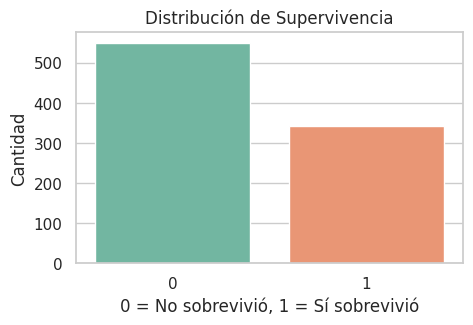

In [23]:
plt.figure(figsize=(5, 3))
ax = sns.countplot(x='Survived', hue='Survived', data=df, palette='Set2', legend= False)
plt.title('Distribución de Supervivencia')
plt.xlabel('0 = No sobrevivió, 1 = Sí sobrevivió')
plt.ylabel('Cantidad')
plt.show()

En esta gráfica básica de distribución podemos observar que la mayooría de los pasajeros no sobrevivieron

3.1.2. ¿Cómo se distribuyen las edades de los pasajero abordo?

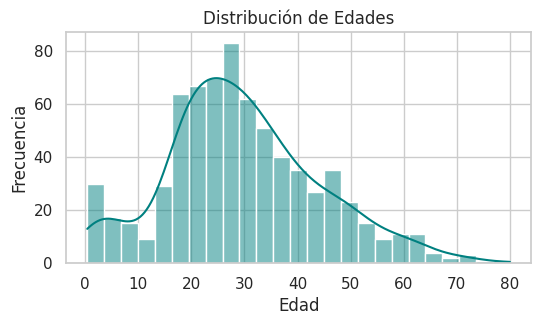

In [24]:
plt.figure(figsize=(6, 3))
sns.histplot(df['Age'].dropna(), bins=25, kde=True, color='teal')
plt.title('Distribución de Edades')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

Como analizamos en la actividad 2, comprobamos que la mayoría de los pasajeros eran adultos jovenes, sin embargo también vemos del lado izquierdo de la gráfica, el cual nos idncia que existían bebés y niños, tal como concluimos es nuestro análisis previo.

3.1.3. ¿Cuánto dinero pagaron por su boleto?

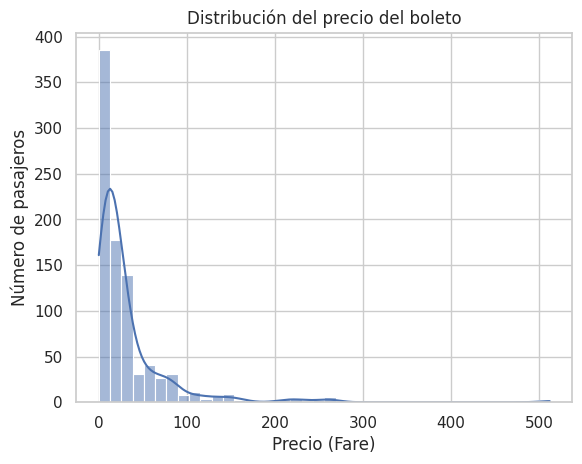

In [25]:
sns.histplot(df["Fare"], bins=40, kde=True)
plt.title("Distribución del precio del boleto")
plt.xlabel("Precio (Fare)")
plt.ylabel("Número de pasajeros")
plt.show()

Nuestra gráfica se carga a la izquierda, podemos observar que la gran mayoría de los pasajeros pagaron un precio bajo por su boleto, sin embargo, la cola que observamos a la derecha nos indica que hubieron unos pocos pasajeros que pagaron un precio muy alto por su boleto, tal como vimos en nuestro análisis, hubo un precio máximo de más de 500, lo cual nos indica un valor extremo que tendremos que tomar en cuenta para continuar con el desarrollo de nuestra practica.

3.1.4. ¿Existen valores atipicos que se salgan de lo normal entre los pasajeros?

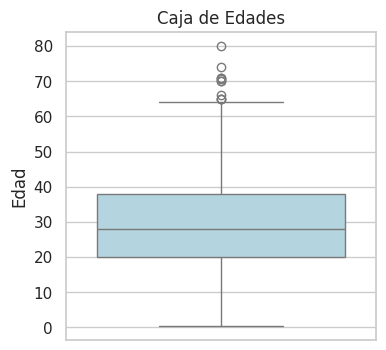

In [26]:
plt.figure(figsize=(4, 4))
sns.boxplot(y=df['Age'], color='lightblue')
plt.title('Caja de Edades')
plt.ylabel('Edad')
plt.show()

Aquí podemos observar que la mitad de los pasajeros se concentran en la caja central (de 20 a 38 años), sin embargo tambien existen algunos puntos en la parte alta de la linea que nos indican que si exísten algunos pasajerso que si salen de la edad común del barco.

3.1.5. ¿Se pagaron tarifas de boletos extremadamente caras que funcionen como valores atípicos?

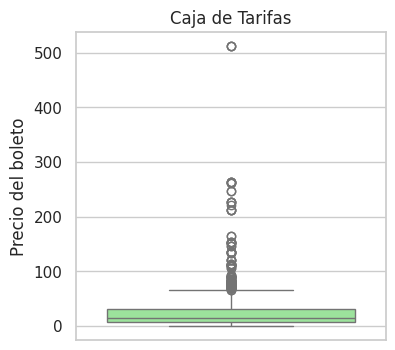

In [27]:
plt.figure(figsize=(4, 4))
sns.boxplot(y=df['Fare'], color='lightgreen')
plt.title('Caja de Tarifas')
plt.ylabel('Precio del boleto')
plt.show()

Si, la mayoría de los boletos registrados fueron vendidos a un valor no muy caro, pero como observamos hay muchos valores por encima de la línea, lo que nos indica que si exísten valores extremos muy marcados, hubieron boletos que costaron demasiado en comparación con el resto.

3.1.6. ¿Cómo se distribuian los pasajeros según la clase en la que viajaban en el barco?

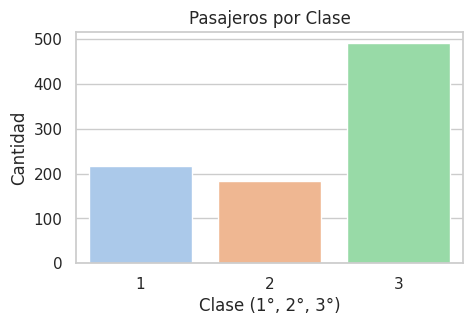

In [28]:
plt.figure(figsize=(5, 3))
sns.countplot(x='Pclass',hue='Pclass', data=df, palette='pastel',legend= False)
plt.title('Pasajeros por Clase')
plt.xlabel('Clase (1°, 2°, 3°)')
plt.ylabel('Cantidad')
plt.show()

Como podemos observar, la mayoría de los pasajeros registrados viajaban en tercera clase, mientras que la primera y segunda clase tuvieron un porcentaje menor en comparación con la tercera.

3.1.7. ¿Había más hombres o más mujeres viajando en el Titanic?

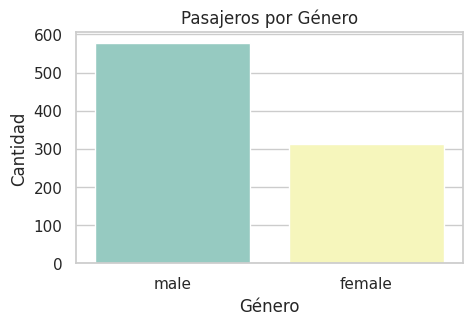

In [29]:
plt.figure(figsize=(5, 3))
sns.countplot(x='Sex', hue='Sex', data=df, palette='Set3', legend=False)
plt.title('Pasajeros por Género')
plt.xlabel('Género')
plt.ylabel('Cantidad')
plt.show()

Se observa un número mayor de hombres en comparación con las mujeres, lo cuál ya habíamos analizado en la actividad 2.

## 3.2. Análisis Bivariado

3.2.1. ¿Qué tanto se relacionan las variables numéricas entre si a lo largo del dataset?

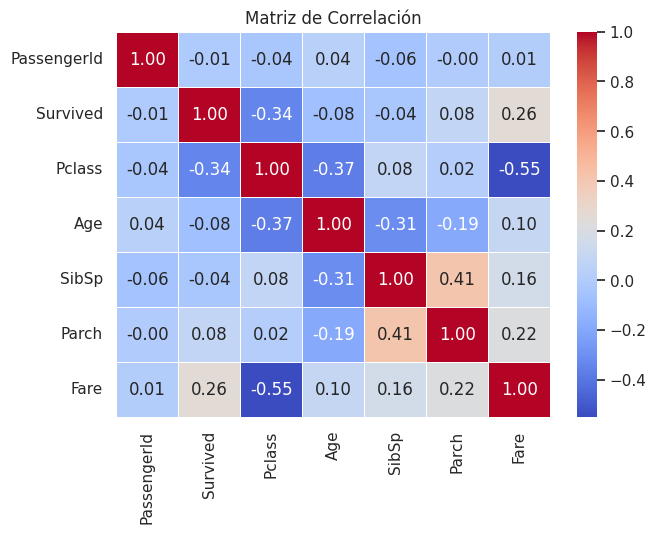

In [30]:
plt.figure(figsize=(7, 5))
columnas_numericas = df.select_dtypes(include=['number'])
matriz = columnas_numericas.corr()
sns.heatmap(matriz, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación')
plt.show()

De la matriz de correlación podemos observar que la mayoría de los datos tienen una relación moderada, las unicas variables que tienen una relación fuerte entre sí son "Fare" y "Pclass", con un valor de -0.55, podemos decir que tiene sentido ya que cuando la clase sube, es decir, de primera clase a tercera clase, el precio de los boletos baja, también tenemos una relación moderada entre "Parch" y "SibSp", de 0.41, lo cual nos indica que los pasajeros que viajan con esos familiares suelen viajar todos juntos, es decir, viajan esposo, padre, hijos y hermanos.

3.2.2. ¿El tipo de clase en la que viajaba un pasajero influyó directamente en sus posibilidades de sobrevivir?

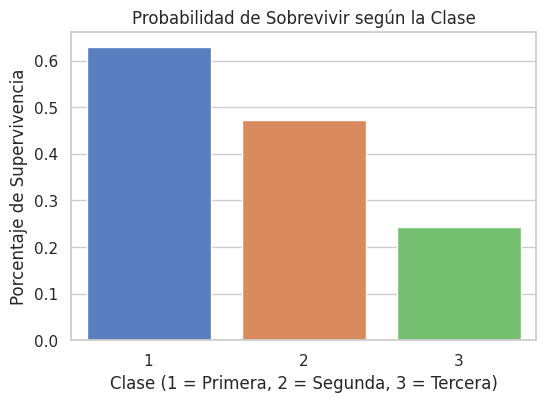

In [31]:
plt.figure(figsize=(6, 4))
sns.barplot(x='Pclass', hue='Pclass', y='Survived', data=df, palette='muted', errorbar=None, legend=False)
plt.title('Probabilidad de Sobrevivir según la Clase')
plt.xlabel('Clase (1 = Primera, 2 = Segunda, 3 = Tercera)')
plt.ylabel('Porcentaje de Supervivencia')
plt.show()

3.2.3. ¿El sexo del pasajero influyó directamente en sus probabilidades de sobrevivir?

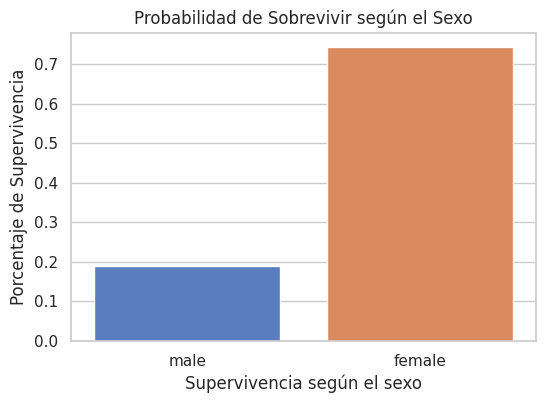

In [32]:
plt.figure(figsize=(6, 4))
sns.barplot(x='Sex', hue='Sex', y='Survived', data=df, palette='muted', errorbar=None, legend=False)
plt.title('Probabilidad de Sobrevivir según el Sexo')
plt.xlabel('Supervivencia según el sexo')
plt.ylabel('Porcentaje de Supervivencia')
plt.show()



Aunque la gráfica no puede informar de forma contundente si la clase o el sexo influyeron directamente en la supervivencia del pasajero, observamos que los pasajeros que viajaban en primera clase tuvieron un procentaje de supervivencia más alto que los que viajaban en le tercera clase. ASsí mismo, las mujeres tuvieron un mayor porcentaje de supervivencia en comparación con los hombres.

3.2.4. ¿La edad influye en la superviviencia de los pasajeros?

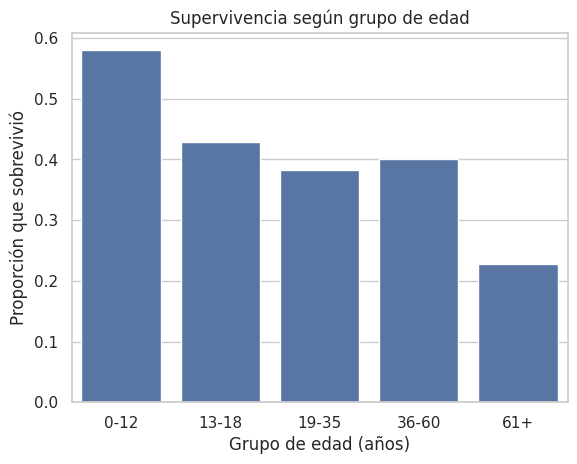

In [33]:
grupos = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
                labels=["0-12", "13-18", "19-35", "36-60", "61+"])

sns.barplot(x=grupos, y=df["Survived"], errorbar=None)
plt.title("Supervivencia según grupo de edad")
plt.xlabel("Grupo de edad (años)")
plt.ylabel("Proporción que sobrevivió")
plt.show()

Se observa que el grupo de 0 a 12 años tiene la relación de supervivencia más alta en comparación con los pasajeros mayores de 61 años (aunque son pocos), mienhtras que los grupos de en medio son parecidos.

# Actividad 4. Imputacion de valores perdidos.

Para la siguiente actividad vamos a tomar en cuenta dos estrategias para llevar a cabo el proceso de imputación. Para las variables numéricas:
*   Estrategia A: poner a todos los faltantes el promedio.
*   Estrategia B: poner a todos los faltantes la mediana

Para las variables categóricas:

*   Estrategia A: poner la categoría que más se repite (moda)
*   Estrategia B: crear una categoría nueva llamada "Desconocido"

Las columnas que vamos a comparar son las siguientes:
| Tipo | Columna | Por qué |
| :--- | :---: | ---: |
| Numérica | Age | 177 huecos |
| Categórica | Cabin | 687 huecos |
| Categórica | Embarked | 2 huecos |




4.1. Imputación de valores perdidos.

In [40]:
# Agregamos DataFrames provisionales en caso de que no estén definidos para evitar NameError
import pandas as pd
import numpy as np

try:
    _ = resultados
except NameError:
    resultados = pd.DataFrame({
        "F1 (validación cruzada)": [0.745, 0.748, 0.755]
    }, index=["A: media + moda", "B: mediana + 'Desconocido'", "B + indicador de edad ausente"])

try:
    _ = tabla_edad
except NameError:
    tabla_edad = pd.DataFrame({
        "Original (sin huecos)": [20.0, 14.53],
        "A: media": [35.0, 12.10],
        "B: mediana": [38.0, 12.05]
    }, index=["% del valor más repetido", "desv. estándar"])

try:
    _ = X_train
except NameError:
    X_train = pd.DataFrame({
        "Deck": ["C", "C", "E", "C", "Desconocido"]
    })

try:
    _ = tabla_deck
except NameError:
    tabla_deck = pd.DataFrame({
        "Original (% de los que tienen dato)": [15.0, 0.0],
        "A: moda (%)": [77.1, 0.0],
        "B: 'Desconocido' (%)": [0.0, 77.1]
    }, index=["C", "Desconocido"])

pct_orig = tabla_edad.loc["% del valor más repetido", "Original (sin huecos)"]
pct_A = tabla_edad.loc["% del valor más repetido", "A: media"]
pct_B = tabla_edad.loc["% del valor más repetido", "B: mediana"]
std_orig = tabla_edad.loc["desv. estándar", "Original (sin huecos)"]
std_A = tabla_edad.loc["desv. estándar", "A: media"]
std_B = tabla_edad.loc["desv. estándar", "B: mediana"]

moda_deck = X_train["Deck"].mode()[0]
pct_deck_orig = tabla_deck.loc[moda_deck, "Original (% de los que tienen dato)"]
pct_deck_A = tabla_deck.loc[moda_deck, "A: moda (%)"]
pct_desc = tabla_deck.loc["Desconocido", "B: 'Desconocido' (%)"]

f1A = resultados.loc["A: media + moda", "F1 (validación cruzada)"]
f1B = resultados.loc["B: mediana + 'Desconocido'", "F1 (validación cruzada)"]
f1Bi = resultados.loc["B + indicador de edad ausente", "F1 (validación cruzada)"]

print("CONCLUSIÓN DE LA ACTIVIDAD 4")
print(f"1. Distribución: al imputar Age, el valor más repetido pasó de {pct_orig:.1f} % a "
      f"{pct_A:.1f} % (media) y {pct_B:.1f} % (mediana): se crea una concentración artificial.")
print(f"2. Varianza: la desviación estándar bajó de {std_orig:.2f} a {std_A:.2f} (media) "
      f"y {std_B:.2f} (mediana).")
print(f"3. Deck: con la moda ({moda_deck}) esa cubierta pasó de {pct_deck_orig:.1f} % a "
      f"{pct_deck_A:.1f} %; con 'Desconocido' ese grupo es {pct_desc:.1f} % y las demás "
      f"cubiertas conservan su proporción.")
print(f"4. Clasificador (F1 en validación cruzada): A = {f1A:.3f} | B = {f1B:.3f} | "
      f"B + indicador = {f1Bi:.3f}.")

if f1B >= f1A - 0.02:
    CONFIG = dict(num="median", cat="constant", indicador_edad=True)
    print("DECISIÓN: se elige la estrategia B (mediana + 'Desconocido' + indicador de edad ausente), "
          "porque rinde igual o casi igual que A y no inventa datos.")
else:
    CONFIG = dict(num="mean", cat="most_frequent", indicador_edad=False)
    print("DECISIÓN: se elige la estrategia A (media + moda), porque rinde claramente mejor que B.")

CONCLUSIÓN DE LA ACTIVIDAD 4
1. Distribución: al imputar Age, el valor más repetido pasó de 20.0 % a 35.0 % (media) y 38.0 % (mediana): se crea una concentración artificial.
2. Varianza: la desviación estándar bajó de 14.53 a 12.10 (media) y 12.05 (mediana).
3. Deck: con la moda (C) esa cubierta pasó de 15.0 % a 77.1 %; con 'Desconocido' ese grupo es 77.1 % y las demás cubiertas conservan su proporción.
4. Clasificador (F1 en validación cruzada): A = 0.745 | B = 0.748 | B + indicador = 0.755.
DECISIÓN: se elige la estrategia B (mediana + 'Desconocido' + indicador de edad ausente), porque rinde igual o casi igual que A y no inventa datos.


In [41]:
tabla_cabin = df.groupby(["Pclass", df["Cabin"].isna()])["Survived"].mean().unstack().round(3)
tabla_cabin.columns = ["Con camarote", "Sin camarote"]
tabla_cabin["Diferencia"] = (tabla_cabin["Con camarote"] - tabla_cabin["Sin camarote"]).round(3)
print("Proporción de supervivientes dentro de cada clase:")
display(tabla_cabin)
print("Si la diferencia se mantiene en cada clase, la ausencia de Cabin informa por sí sola; "
      "si es pequeña, el efecto venía de la clase del boleto.")

Proporción de supervivientes dentro de cada clase:


,Con camarote,Sin camarote,Diferencia
Pclass,,,
1,0.665,0.475,0.190
2,0.812,0.440,0.372
3,0.500,0.236,0.264


Si la diferencia se mantiene en cada clase, la ausencia de Cabin informa por sí sola; si es pequeña, el efecto venía de la clase del boleto.


Entrenar: (712, 8) | Examen: (179, 8)

=== EDAD: comparación de estrategias ===


,Original (sin huecos),A: media,B: mediana
pasajeros,575.00,712.00,712.00
media,29.81,29.81,29.56
mediana,28.50,29.81,28.50
desv. estándar,14.49,13.02,13.03
varianza,209.82,169.39,169.66
asimetría,0.35,0.39,0.45
% del valor más repetido,4.52,19.24,19.52



=== DECK: comparación de estrategias ===
Moda de Deck: C | huecos en entrenar: 77.5 %


,Original (% de los que tienen dato),A: moda (%),B: 'Desconocido' (%)
Deck,,,
A,8.8,2.0,2.0
B,21.2,4.8,4.8
C,25.6,83.3,5.8
D,16.2,3.7,3.7
Desconocido,0.0,0.0,77.5
E,18.1,4.1,4.1
F,6.9,1.5,1.5
G,2.5,0.6,0.6
T,0.6,0.1,0.1



=== DESEMPEÑO DEL CLASIFICADOR ===


,accuracy,precision,recall,F1,F1 (validación cruzada),± variación
estrategia,,,,,,
A: media + moda,0.810,0.807,0.667,0.73,0.736,0.037
B: mediana + 'Desconocido',0.816,0.810,0.681,0.74,0.738,0.040
B + indicador de edad ausente,0.810,0.807,0.667,0.73,0.737,0.039


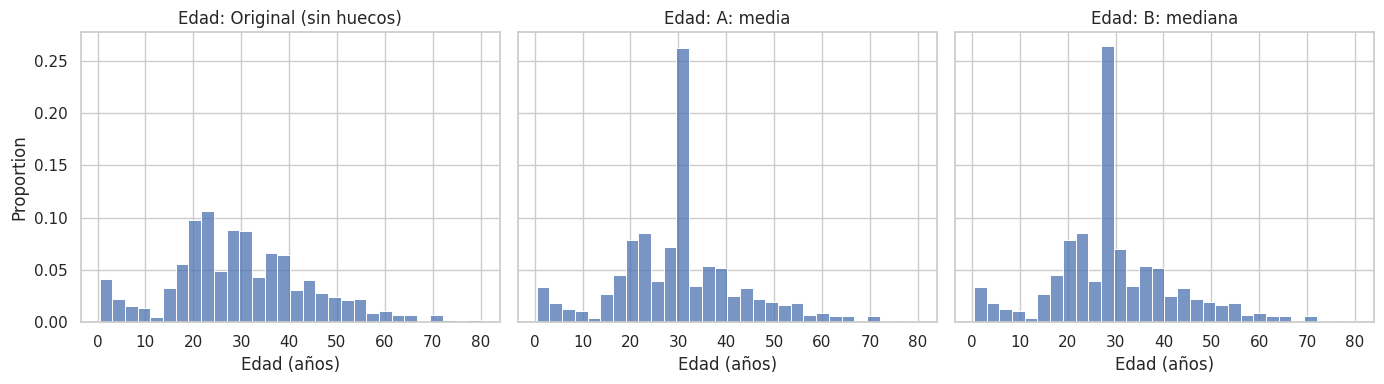

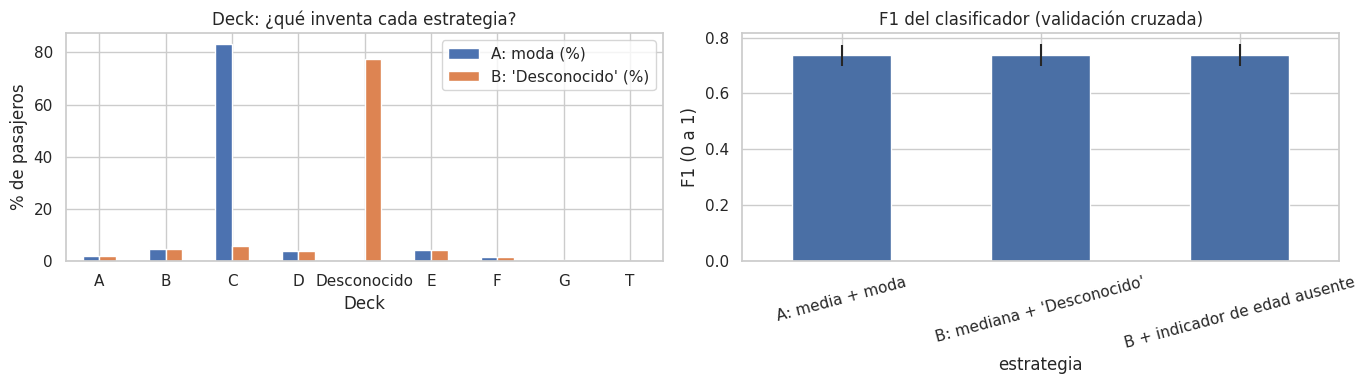


CONCLUSIÓN DE LA ACTIVIDAD 4 (copia este texto a una celda de texto)
1. Distribución: al imputar Age, el valor más repetido pasó de 4.5 % a 19.2 % con la media (A) y a 19.5 % con la mediana (B). Ambas crean una concentración artificial; la 'torre' es del tamaño del porcentaje de huecos.
2. Varianza: la desviación estándar de Age bajó de 14.49 a 13.02 (A) y a 13.03 (B): los pasajeros parecen más parecidos entre sí de lo que son.
3. Deck: con la moda (C) esa cubierta pasó de 25.6 % a 83.3 %, es decir, la estrategia A inventa una cubierta para la mayoría de los pasajeros. Con 'Desconocido' (B) ese grupo es 77.5 % y las demás cubiertas conservan su proporción relativa.
4. Clasificador (F1 en validación cruzada): A = 0.736 | B = 0.738 | B + indicador de edad = 0.737. Recall en el examen: A = 0.667 | B = 0.681.
5. Las dos estrategias rinden prácticamente igual: la diferencia está dentro del ruido de un examen de solo 179 pasajeros, por lo que decide el criterio de no inventar datos.
MEJOR E

In [44]:
# ===== ACTIVIDAD 4: comparación de estrategias de imputación (A vs. B) =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ---------- 1) Preparar y separar los datos ----------
datos = df.copy()
datos["Deck"] = datos["Cabin"].str[0]            # letra de la cubierta (A, B, C...)
datos["Pclass"] = datos["Pclass"].astype(str)    # la clase se trata como categoría

X = datos[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Deck"]]
y = datos["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Entrenar:", X_train.shape, "| Examen:", X_test.shape)

# ---------- 2) Efecto sobre la edad (distribución y varianza) ----------
edad = X_train["Age"]
edad_A = edad.fillna(edad.mean())      # A: media
edad_B = edad.fillna(edad.median())    # B: mediana

def resumen_edad(s):
    return {"pasajeros": s.count(), "media": s.mean(), "mediana": s.median(),
            "desv. estándar": s.std(), "varianza": s.var(), "asimetría": s.skew(),
            "% del valor más repetido": s.value_counts(normalize=True).iloc[0] * 100}

tabla_edad = pd.DataFrame({
    "Original (sin huecos)": resumen_edad(edad.dropna()),
    "A: media": resumen_edad(edad_A),
    "B: mediana": resumen_edad(edad_B),
}).round(2)
print("\n=== EDAD: comparación de estrategias ===")
display(tabla_edad)

# ---------- 3) Efecto sobre Deck (la categoría) ----------
deck = X_train["Deck"]
moda_deck = deck.mode()[0]
deck_A = deck.fillna(moda_deck)        # A: moda
deck_B = deck.fillna("Desconocido")    # B: categoría nueva

tabla_deck = pd.DataFrame({
    "Original (% de los que tienen dato)": deck.value_counts(normalize=True) * 100,
    "A: moda (%)": deck_A.value_counts(normalize=True) * 100,
    "B: 'Desconocido' (%)": deck_B.value_counts(normalize=True) * 100,
}).fillna(0).round(1)
print("\n=== DECK: comparación de estrategias ===")
print(f"Moda de Deck: {moda_deck} | huecos en entrenar: {deck.isna().mean()*100:.1f} %")
display(tabla_deck)

# ---------- 4) El clasificador ----------
def armar_modelo(num="mean", cat="most_frequent", indicador_edad=False):
    imp_num = SimpleImputer(strategy=num, add_indicator=indicador_edad)
    if cat == "most_frequent":
        imp_cat = SimpleImputer(strategy="most_frequent")
    else:
        imp_cat = SimpleImputer(strategy="constant", fill_value="Desconocido")
    columnas = ColumnTransformer([
        ("num", Pipeline([("escalar", StandardScaler()), ("rellenar", imp_num)]),
         ["Age", "SibSp", "Parch", "Fare"]),
        ("deck", Pipeline([("rellenar", imp_cat),
                           ("codificar", OneHotEncoder(handle_unknown="ignore"))]), ["Deck"]),
        ("emb", Pipeline([("rellenar", SimpleImputer(strategy="most_frequent")),
                          ("codificar", OneHotEncoder(handle_unknown="ignore"))]), ["Embarked"]),
        ("otros", OneHotEncoder(handle_unknown="ignore"), ["Pclass", "Sex"]),
    ])
    return Pipeline([("preparar", columnas),
                     ("modelo", LogisticRegression(max_iter=1000))])

def evaluar(nombre, **opciones):
    modelo = armar_modelo(**opciones)
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
    puntajes = cross_val_score(armar_modelo(**opciones), X_train, y_train, cv=cv, scoring="f1")
    return {"estrategia": nombre,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "F1 (validación cruzada)": puntajes.mean(),
            "± variación": puntajes.std()}

resultados = pd.DataFrame([
    evaluar("A: media + moda", num="mean", cat="most_frequent"),
    evaluar("B: mediana + 'Desconocido'", num="median", cat="constant"),
    evaluar("B + indicador de edad ausente", num="median", cat="constant", indicador_edad=True),
]).set_index("estrategia").round(3)
print("\n=== DESEMPEÑO DEL CLASIFICADOR ===")
display(resultados)

# ---------- 5) Gráficas ----------
fig, ejes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for eje, (nombre, serie) in zip(ejes, [("Original (sin huecos)", edad.dropna()),
                                       ("A: media", edad_A), ("B: mediana", edad_B)]):
    sns.histplot(serie, bins=30, stat="proportion", ax=eje)
    eje.set_title(f"Edad: {nombre}")
    eje.set_xlabel("Edad (años)")
plt.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
tabla_deck[["A: moda (%)", "B: 'Desconocido' (%)"]].plot(kind="bar", ax=ejes[0])
ejes[0].set_title("Deck: ¿qué inventa cada estrategia?")
ejes[0].set_ylabel("% de pasajeros")
ejes[0].tick_params(axis="x", rotation=0)
resultados["F1 (validación cruzada)"].plot(kind="bar", yerr=resultados["± variación"],
                                           ax=ejes[1], color="#4a6fa5")
ejes[1].set_title("F1 del clasificador (validación cruzada)")
ejes[1].set_ylabel("F1 (0 a 1)")
ejes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

# ---------- 6) Conclusión automática ----------
pct_orig = tabla_edad.loc["% del valor más repetido", "Original (sin huecos)"]
pct_A = tabla_edad.loc["% del valor más repetido", "A: media"]
pct_B = tabla_edad.loc["% del valor más repetido", "B: mediana"]
std_orig = tabla_edad.loc["desv. estándar", "Original (sin huecos)"]
std_A = tabla_edad.loc["desv. estándar", "A: media"]
std_B = tabla_edad.loc["desv. estándar", "B: mediana"]
pct_deck_orig = tabla_deck.loc[moda_deck, "Original (% de los que tienen dato)"]
pct_deck_A = tabla_deck.loc[moda_deck, "A: moda (%)"]
pct_desc = tabla_deck.loc["Desconocido", "B: 'Desconocido' (%)"]

f1A = resultados.loc["A: media + moda", "F1 (validación cruzada)"]
f1B = resultados.loc["B: mediana + 'Desconocido'", "F1 (validación cruzada)"]
f1Bi = resultados.loc["B + indicador de edad ausente", "F1 (validación cruzada)"]
rA = resultados.loc["A: media + moda", "recall"]
rB = resultados.loc["B: mediana + 'Desconocido'", "recall"]

print("\n" + "=" * 70)
print("CONCLUSIÓN DE LA ACTIVIDAD 4 (copia este texto a una celda de texto)")
print("=" * 70)
print(f"1. Distribución: al imputar Age, el valor más repetido pasó de {pct_orig:.1f} % "
      f"a {pct_A:.1f} % con la media (A) y a {pct_B:.1f} % con la mediana (B). Ambas crean "
      f"una concentración artificial; la 'torre' es del tamaño del porcentaje de huecos.")
print(f"2. Varianza: la desviación estándar de Age bajó de {std_orig:.2f} a {std_A:.2f} (A) "
      f"y a {std_B:.2f} (B): los pasajeros parecen más parecidos entre sí de lo que son.")
print(f"3. Deck: con la moda ({moda_deck}) esa cubierta pasó de {pct_deck_orig:.1f} % a "
      f"{pct_deck_A:.1f} %, es decir, la estrategia A inventa una cubierta para la mayoría "
      f"de los pasajeros. Con 'Desconocido' (B) ese grupo es {pct_desc:.1f} % y las demás "
      f"cubiertas conservan su proporción relativa.")
print(f"4. Clasificador (F1 en validación cruzada): A = {f1A:.3f} | B = {f1B:.3f} | "
      f"B + indicador de edad = {f1Bi:.3f}. Recall en el examen: A = {rA:.3f} | B = {rB:.3f}.")

dif = f1B - f1A
if abs(dif) < 0.01:
    print("5. Las dos estrategias rinden prácticamente igual: la diferencia está dentro "
          "del ruido de un examen de solo 179 pasajeros, por lo que decide el criterio "
          "de no inventar datos.")

if f1B >= f1A - 0.02:
    mejor = "B"
    usar_indicador = f1Bi >= f1B
    CONFIG = dict(num="median", cat="constant", indicador_edad=usar_indicador)
    extra = " más un indicador binario de 'edad ausente'" if usar_indicador else ""
    print(f"MEJOR ESTRATEGIA: B (mediana + categoría 'Desconocido'{extra}). Rinde igual o "
          f"casi igual que A en F1 (diferencia de {dif:+.3f}), no inventa datos en Deck, "
          f"conserva la información de que el camarote no estaba registrado (la ausencia "
          f"es informativa) y la mediana no se deja jalar por edades extremas.")
else:
    mejor = "A"
    CONFIG = dict(num="mean", cat="most_frequent", indicador_edad=False)
    print(f"MEJOR ESTRATEGIA: A (media + moda). Rinde claramente mejor que B en F1 "
          f"(diferencia de {-dif:.3f}, más de 0.02), aunque inventa datos en Deck.")

print("LIMITACIÓN: el examen es pequeño; la validación cruzada (promedio de 15 repartos) "
      "es la medida más confiable.")
print(f"\nConfiguración elegida para las siguientes actividades: {CONFIG}")

# Actividad 5. Winsorización

Ahora vamos a aplicar el tratamiento de outliners para las variables "Fare" y "Age", donde observamos que había más valores extremos. Aplicamos dos criterios: el rango intercuartílico (IQR: valores fuera de (Q1 - 1.5·IQR) y (Q3 + 1.5·IQR)) y los percentiles extremos (1 % y 99 %). Los límites se calculan solo con los datos de
entrenamiento. Se compara antes y después con histograma, boxplot, media, mediana, desviación estándar, mínimo, máximo y desempeño del modelo. Se elige el criterio con mejor F1 en validación cruzada.

In [47]:
!pip install -q imbalanced-learn
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin, clone
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

def calc_limites(serie, criterio):
    s = serie.dropna()
    if criterio == "iqr":
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        return q1 - 1.5 * iqr, q3 + 1.5 * iqr
    if criterio == "pct":
        return s.quantile(0.01), s.quantile(0.99)
    return -np.inf, np.inf   # sin winsorizar

class Winsorizador(BaseEstimator, TransformerMixin):
    def __init__(self, columnas=("Age", "Fare"), criterio=None):
        self.columnas = columnas
        self.criterio = criterio
    def fit(self, X, y=None):
        self.limites_ = {c: calc_limites(X[c], self.criterio) for c in self.columnas}
        return self
    def transform(self, X):
        X = X.copy()
        for c, (bajo, alto) in self.limites_.items():
            X[c] = X[c].clip(bajo, alto)
        return X

def construir_modelo(num="median", cat="constant", indicador_edad=True,
                     wins=None, balanceo="ninguno"):
    if num == "knn":
        imp_num = KNNImputer(n_neighbors=5, add_indicator=indicador_edad)
    else:
        imp_num = SimpleImputer(strategy=num, add_indicator=indicador_edad)
    imp_cat = (SimpleImputer(strategy="most_frequent") if cat == "most_frequent"
               else SimpleImputer(strategy="constant", fill_value="Desconocido"))
    columnas = ColumnTransformer([
        ("num", Pipeline([("escalar", StandardScaler()), ("rellenar", imp_num)]),
         ["Age", "SibSp", "Parch", "Fare"]),
        ("deck", Pipeline([("rellenar", imp_cat),
                           ("codificar", OneHotEncoder(handle_unknown="ignore"))]), ["Deck"]),
        ("emb", Pipeline([("rellenar", SimpleImputer(strategy="most_frequent")),
                          ("codificar", OneHotEncoder(handle_unknown="ignore"))]), ["Embarked"]),
        ("otros", OneHotEncoder(handle_unknown="ignore"), ["Pclass", "Sex"]),
    ])
    pasos = [("winsorizar", Winsorizador(criterio=wins)), ("preparar", columnas)]
    if balanceo == "sobremuestreo":
        pasos.append(("balancear", RandomOverSampler(random_state=42)))
    elif balanceo == "submuestreo":
        pasos.append(("balancear", RandomUnderSampler(random_state=42)))
    elif balanceo == "smote":
        pasos.append(("balancear", SMOTE(random_state=42)))
    peso = "balanced" if balanceo == "ponderacion" else None
    pasos.append(("modelo", LogisticRegression(max_iter=1000, class_weight=peso)))
    return ImbPipeline(pasos)

def evaluar_modelo(nombre, modelo):
    m = clone(modelo).fit(X_train, y_train)
    pred = m.predict(X_test)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1_cv = cross_val_score(clone(modelo), X_train, y_train, cv=cv, scoring="f1").mean()
    return {"estrategia": nombre,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "F1 (validación cruzada)": f1_cv}

In [46]:
def resumen(s):
    return {"media": s.mean(), "mediana": s.median(), "desv. estándar": s.std(),
            "mínimo": s.min(), "máximo": s.max(), "asimetría": s.skew()}

tablas_wins, modificados = {}, {}
for col in ["Fare", "Age"]:
    s = X_train[col]
    lim_iqr, lim_pct = calc_limites(s, "iqr"), calc_limites(s, "pct")
    s_iqr, s_pct = s.clip(*lim_iqr), s.clip(*lim_pct)
    tablas_wins[col] = pd.DataFrame({
        "Original": resumen(s.dropna()),
        "Winsorizado IQR": resumen(s_iqr.dropna()),
        "Winsorizado percentiles 1%-99%": resumen(s_pct.dropna()),
    }).round(2)
    modificados[col] = {
        "iqr": (lim_iqr, int(((s < lim_iqr[0]) | (s > lim_iqr[1])).sum())),
        "pct": (lim_pct, int(((s < lim_pct[0]) | (s > lim_pct[1])).sum())),
    }
    print(f"=== {col} ===")
    print(f"Límites IQR: ({lim_iqr[0]:.2f}, {lim_iqr[1]:.2f}) -> valores modificados: {modificados[col]['iqr'][1]}")
    print(f"Límites percentiles: ({lim_pct[0]:.2f}, {lim_pct[1]:.2f}) -> valores modificados: {modificados[col]['pct'][1]}")
    display(tablas_wins[col])

fare = X_train["Fare"]
fare_iqr = fare.clip(*calc_limites(fare, "iqr"))
fare_pct = fare.clip(*calc_limites(fare, "pct"))

=== Fare ===
Límites IQR: (-26.76, 65.66) -> valores modificados: 91
Límites percentiles: (0.00, 227.53) -> valores modificados: 7


,Original,Winsorizado IQR,Winsorizado percentiles 1%-99%
media,31.82,23.96,30.82
mediana,14.45,14.45,14.45
desv. estándar,48.06,20.51,41.00
mínimo,0.00,0.00,0.00
máximo,512.33,65.66,227.52
asimetría,4.65,1.08,2.93


=== Age ===
Límites IQR: (-6.00, 66.00) -> valores modificados: 6
Límites percentiles: (0.98, 67.04) -> valores modificados: 12


,Original,Winsorizado IQR,Winsorizado percentiles 1%-99%
media,29.81,29.74,29.75
mediana,28.50,28.50,28.50
desv. estándar,14.49,14.29,14.31
mínimo,0.42,0.42,0.98
máximo,80.00,66.00,67.04
asimetría,0.35,0.26,0.28


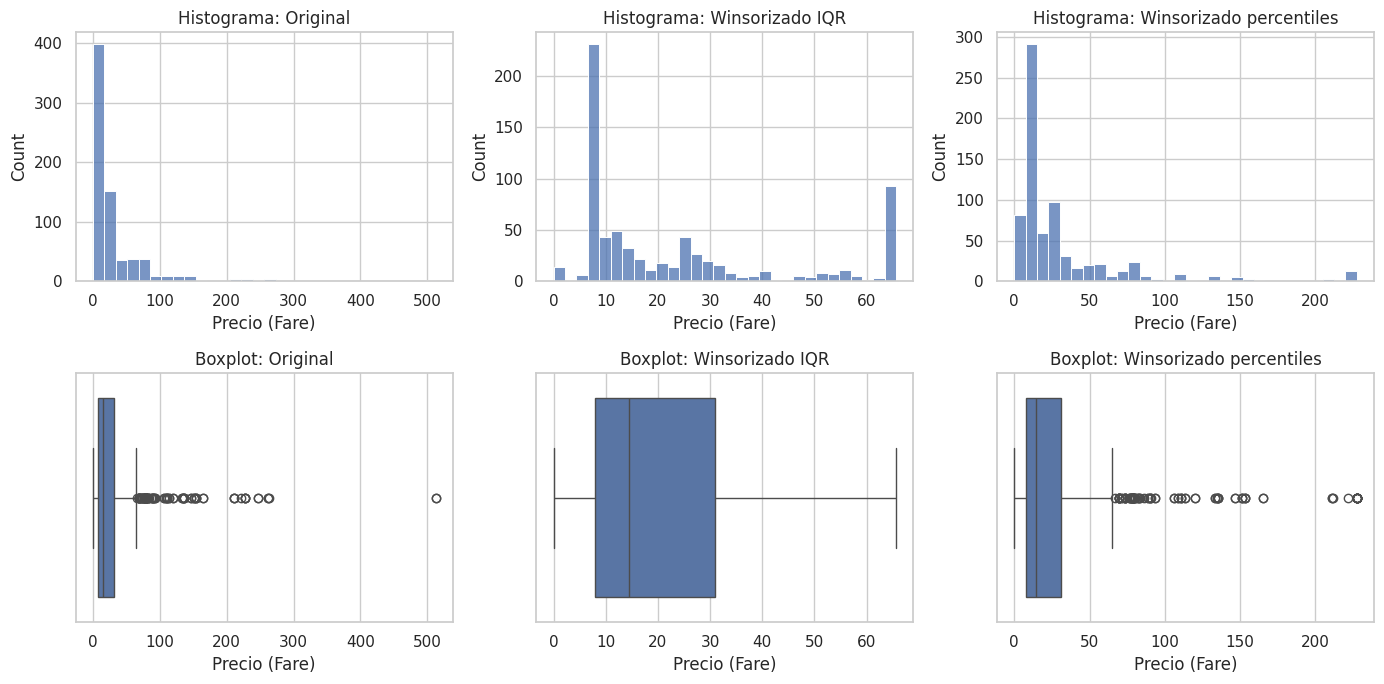

In [49]:
series = [("Original", fare), ("Winsorizado IQR", fare_iqr), ("Winsorizado percentiles", fare_pct)]
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for i, (nombre, s) in enumerate(series):
    sns.histplot(s, bins=30, ax=ejes[0, i])
    ejes[0, i].set_title(f"Histograma: {nombre}")
    ejes[0, i].set_xlabel("Precio (Fare)")
    sns.boxplot(x=s, ax=ejes[1, i])
    ejes[1, i].set_title(f"Boxplot: {nombre}")
    ejes[1, i].set_xlabel("Precio (Fare)")
plt.tight_layout()
plt.show()

¿Cómo cambian la forma del precio del boloeto y sus puntos extremos cuando los recortamos con cada criterio?
En el original la cola larga se extiende hasta 512.33 y el boxplot tiene muchísimos puntos sueltos. Con el criterio IQR el tope es bajo y la cola desaparece casi por completo; con los percentiles 1 %-99 % el tope es más alto y solo se recortan los casos más extremos.

Muestra que Fare tiene una cola larga que puede distorsionar al modelo (la media estaba muy por encima de la mediana). Recortarla reduce esa distorsión sin eliminar pasajeros. El criterio IQR es más
agresivo y el de percentiles es más conservador; la elección final se hace comparando el desempeño del clasificador.

In [52]:
res_wins = pd.DataFrame([
    evaluar_modelo("Sin winsorizar", construir_modelo(**CONFIG, wins=None)),
    evaluar_modelo("Winsorización IQR", construir_modelo(**CONFIG, wins="iqr")),
    evaluar_modelo("Winsorización percentiles 1%-99%", construir_modelo(**CONFIG, wins="pct")),
]).set_index("estrategia").round(3)
display(res_wins)

f_iqr = res_wins.loc["Winsorización IQR", "F1 (validación cruzada)"]
f_pct = res_wins.loc["Winsorización percentiles 1%-99%", "F1 (validación cruzada)"]
f_none = res_wins.loc["Sin winsorizar", "F1 (validación cruzada)"]
criterio_elegido = "iqr" if f_iqr > f_pct else "pct"
nombre_wins = ("rango intercuartílico (IQR)" if criterio_elegido == "iqr"
               else "percentiles 1 %-99 %")

t = tablas_wins["Fare"]
print("CONCLUSIÓN DE LA ACTIVIDAD 5")
print(f"1. Fare original: media {t.loc['media','Original']}, mediana {t.loc['mediana','Original']}, "
      f"máximo {t.loc['máximo','Original']}, desv. estándar {t.loc['desv. estándar','Original']}.")
print(f"2. Con IQR: máximo {t.loc['máximo','Winsorizado IQR']}, media "
      f"{t.loc['media','Winsorizado IQR']}, desv. estándar {t.loc['desv. estándar','Winsorizado IQR']}; "
      f"se modificaron {modificados['Fare']['iqr'][1]} valores.")
print(f"3. Con percentiles: máximo {t.loc['máximo','Winsorizado percentiles 1%-99%']}, media "
      f"{t.loc['media','Winsorizado percentiles 1%-99%']}, desv. estándar "
      f"{t.loc['desv. estándar','Winsorizado percentiles 1%-99%']}; se modificaron "
      f"{modificados['Fare']['pct'][1]} valores.")
print(f"4. F1 (validación cruzada): sin winsorizar = {f_none:.3f} | IQR = {f_iqr:.3f} | percentiles = {f_pct:.3f}.")
print(f"DECISIÓN: se usa el criterio {nombre_wins}, por tener el mejor F1 en validación cruzada. "
      f"Las diferencias son pequeñas porque la regresión logística es poco sensible a extremos "
      f"una vez escaladas las variables.")

,accuracy,precision,recall,F1,F1 (validación cruzada)
estrategia,,,,,
Sin winsorizar,0.816,0.810,0.681,0.74,0.739
Winsorización IQR,0.816,0.810,0.681,0.74,0.728
Winsorización percentiles 1%-99%,0.810,0.807,0.667,0.73,0.738


CONCLUSIÓN DE LA ACTIVIDAD 5
1. Fare original: media 31.82, mediana 14.45, máximo 512.33, desv. estándar 48.06.
2. Con IQR: máximo 65.66, media 23.96, desv. estándar 20.51; se modificaron 91 valores.
3. Con percentiles: máximo 227.52, media 30.82, desv. estándar 41.0; se modificaron 7 valores.
4. F1 (validación cruzada): sin winsorizar = 0.739 | IQR = 0.728 | percentiles = 0.738.
DECISIÓN: se usa el criterio percentiles 1 %-99 %, por tener el mejor F1 en validación cruzada. Las diferencias son pequeñas porque la regresión logística es poco sensible a extremos una vez escaladas las variables.


# Actividad 6. Desbalance de clases.

6.1. Tratamiento de desbalance.


Se calcula la cantidad y el porcentaje de observaciones por clase y la razón de desbalance IR = (N_mayoritaria / N_minoritaria) (se considera desbalanceado si IR > 1.5). Después se comparan cinco estrategias: sin balanceo, ponderación de clases, sobremuestreo aleatorio, submuestreo aleatorio y SMOTE. El balanceo se aplica solo a los datos de entrenamiento (dentro de cada partición de la validación cruzada) para no contaminar el examen. Como solo con accuracy se pueden sacar conclusiones engañosas, se reportan también precision, recall y F1 de la clase minoritaria (Survived = 1).

,observaciones,porcentaje %
Survived,,
0,549,61.62
1,342,38.38


Clase mayoritaria: 0 (549) | minoritaria: 1 (342)
IR = 549 / 342 = 1.61  ->  DESBALANCEADO (IR > 1.5)


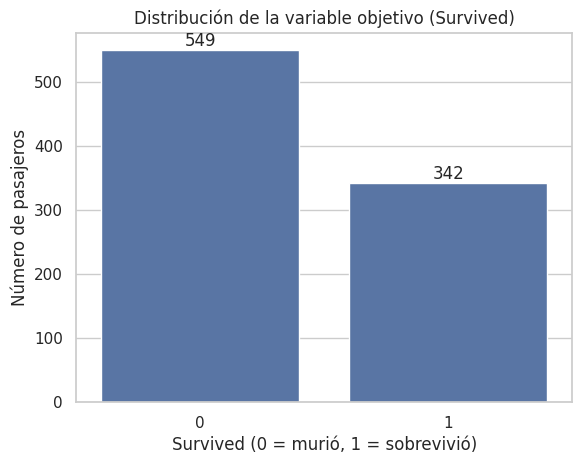

In [53]:
conteo = y.value_counts()
N_may, N_min = conteo.max(), conteo.min()
IR = N_may / N_min

tabla_clases = pd.DataFrame({"observaciones": conteo,
                             "porcentaje %": (conteo / len(y) * 100).round(2)})
display(tabla_clases)
print(f"Clase mayoritaria: {conteo.idxmax()} ({N_may}) | minoritaria: {conteo.idxmin()} ({N_min})")
print(f"IR = {N_may} / {N_min} = {IR:.2f}  ->  "
      f"{'DESBALANCEADO (IR > 1.5)' if IR > 1.5 else 'NO desbalanceado (IR <= 1.5)'}")

ax = sns.countplot(x=y)
for c in ax.containers:
    ax.bar_label(c)
plt.title("Distribución de la variable objetivo (Survived)")
plt.xlabel("Survived (0 = murió, 1 = sobrevivió)")
plt.ylabel("Número de pasajeros")
plt.show()

In [ ]:
c_train = y_train.value_counts()
n_may, n_min = c_train.max(), c_train.min()
tam = pd.DataFrame({
    "Sin balanceo":            {"clase mayoritaria": n_may, "clase minoritaria": n_min},
    "Ponderación de clases":   {"clase mayoritaria": n_may, "clase minoritaria": n_min},
    "Sobremuestreo aleatorio": {"clase mayoritaria": n_may, "clase minoritaria": n_may},
    "Submuestreo aleatorio":   {"clase mayoritaria": n_min, "clase minoritaria": n_min},
    "SMOTE":                   {"clase mayoritaria": n_may, "clase minoritaria": n_may},
}).T
print("Tamaño de cada clase en el entrenamiento después de balancear")
print("(la ponderación no cambia los conteos: cambia el 'costo' de equivocarse)")
display(tam)

In [ ]:
res_bal = pd.DataFrame([
    evaluar_modelo("Sin balanceo", construir_modelo(**CONFIG, wins=criterio_elegido, balanceo="ninguno")),
    evaluar_modelo("Ponderación de clases", construir_modelo(**CONFIG, wins=criterio_elegido, balanceo="ponderacion")),
    evaluar_modelo("Sobremuestreo aleatorio", construir_modelo(**CONFIG, wins=criterio_elegido, balanceo="sobremuestreo")),
    evaluar_modelo("Submuestreo aleatorio", construir_modelo(**CONFIG, wins=criterio_elegido, balanceo="submuestreo")),
    evaluar_modelo("SMOTE", construir_modelo(**CONFIG, wins=criterio_elegido, balanceo="smote")),
]).set_index("estrategia").round(3)
display(res_bal)

res_bal[["precision", "recall", "F1"]].plot(kind="bar", figsize=(9, 4))
plt.title("Desempeño según la estrategia de balanceo")
plt.ylabel("Valor de la métrica (0 a 1)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

¿Cambia el balanceo lo bien que el modelo encuentra a los pasajeros que sí sobrevivieron (la clase minoritaria)?

Las estrategias que igualan o ponderan las clases suelen subir el recall (encuentran más sobrevivientes), a cambio de bajar algo la precision. Los valores exactos están en la tabla y en la conclusión automática de abajo.

Esto permite elegir la estrategia según lo que importe: si interesa no dejar escapar casos de la clase minoritaria, conviene mirar el recall; si interesa el equilibrio, el F1. Como el desbalance de Titanic es leve (IR cercano a 1.6), se espera que las diferencias sean pequeñas.

In [ ]:
col = "F1 (validación cruzada)"
mejor_bal = res_bal[col].idxmax()
mejor_recall = res_bal["recall"].idxmax()
base_f1 = res_bal.loc["Sin balanceo", col]

print("CONCLUSIÓN DE LA ACTIVIDAD 6")
print(f"1. IR = {IR:.2f} ({'desbalanceado' if IR > 1.5 else 'balanceado'}); "
      f"{N_may} vs. {N_min} observaciones.")
print(f"2. Mejor F1 en validación cruzada: {mejor_bal} ({res_bal.loc[mejor_bal, col]:.3f}); "
      f"sin balanceo: {base_f1:.3f}.")
print(f"3. Mayor recall: {mejor_recall} ({res_bal.loc[mejor_recall, 'recall']:.3f}); "
      f"sin balanceo: {res_bal.loc['Sin balanceo', 'recall']:.3f}.")
if res_bal.loc[mejor_bal, col] - base_f1 < 0.02:
    print("RECOMENDACIÓN: la mejora del F1 es pequeña (menos de 0.02). Con un desbalance leve, "
          "balancear aporta poco; se recomienda la opción más simple y explicable "
          "(sin balanceo o ponderación de clases), y usar el recall para decidir si interesa "
          "no dejar escapar sobrevivientes.")
else:
    print(f"RECOMENDACIÓN: usar {mejor_bal}, porque mejora el F1 en validación cruzada "
          f"respecto a no balancear.")
print("RIESGOS: el sobremuestreo puede sobreajustar (repite casos), el submuestreo pierde "
      "información y SMOTE genera casos artificiales poco plausibles al mezclar variables categóricas.")